# Can B(s) be finetuned to perfectly represent reward functions?

Same B, same encoding and same L_rec as in `fb_continual.py` (walker): `B = sqrt(d) * normalize(MLP(s))`, reward normalised to unit second moment, `z_hat = mean(rbar * B)`, reconstruction `rbar ≈ B^T Sigma^-1 z_hat` with a detached coefficient.

Only **B** is trained, with **L_rec only** (no F, no actor, no retention terms).

- **Test 1:** finetune B on ONE task reward at a time. Does the held-out unexplained fraction `eps` of that task ever reach ~0?
- **Test 2:** finetune B on ALL test rewards jointly. Do all `eps` reach ~0 at the same time?

`eps` = fraction of reward energy NOT explained by B on held-out states (same metric as `recon_stats` in the script). Set `CHECKPOINT` to start from your pretrained B, otherwise B starts from random init.

In [120]:
import math, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax, optax
import jax.numpy as jnp
import flax.linen as nn
from flax import serialization

# ---- config ----
DATASET_FOLDER = '../offline_qd/datasets/d4rl'   # folder with walker_rnd.npy, aux_walker.npy, angmomentum_aux_walker.npy
CHECKPOINT = None            # e.g. 'path/to/fb_agent_latest.pickle' (pretrained FB); None = random init of B
N_DATA = 1_000_000           # random subset of dataset states
Z_DIM, HIDDEN = 50, 526      # must match the pretraining run if CHECKPOINT is used
N_LABELED = 100_000           # labeled states D_k used to fit the reward (fixed during finetuning)
N_EST = 4096                 # states per step to estimate Sigma
EVAL_N = 10_000              # states for the held-out eps evaluation
RIDGE = 1e-5
LR = 1e-4
STEPS = 10_000
LOG_EVERY = 500
EPS_PERFECT = 1e-3           # eps below this = "perfect" (0.1% of the reward energy unexplained)
SEED = 0
print(jax.devices())

from tqdm import tqdm
from IPython.display import clear_output

[CudaDevice(id=0)]


In [121]:
# ---- walker rewards (copied from the script) ----
INF = float('inf')

def _sigmoid(x, value_at_1, sigmoid):
    if sigmoid == 'linear':
        scaled = x * (1.0 - value_at_1)
        return jnp.where(jnp.abs(scaled) < 1, 1.0 - scaled, 0.0)
    if sigmoid == 'gaussian':
        scale = math.sqrt(-2 * math.log(value_at_1))
        return jnp.exp(-0.5 * (x * scale) ** 2)
    raise NotImplementedError(sigmoid)

def tolerance(x, lower, upper, margin, sigmoid='linear', value_at_margin=0.0):
    in_bounds = jnp.logical_and(lower <= x, x <= upper)
    d = jnp.where(x < lower, lower - x, x - upper) / margin
    return jnp.where(in_bounds, 1.0, _sigmoid(d, value_at_margin, sigmoid))

def walker_reward(aux, param):
    _STAND_HEIGHT = 1.2
    torso_upright, torso_height = aux[..., 1], aux[..., 2]
    standing = tolerance(torso_height, _STAND_HEIGHT, INF, _STAND_HEIGHT / 2, 'gaussian', 0.1)
    upright = (1 + torso_upright) / 2
    stand_reward = (3 * standing + upright) / 4
    if param == 'flip':
        move_reward = tolerance(aux[..., 3], 5.0, INF, 5.0, 'linear', 0.5)
    elif param == 0:
        move_reward = jnp.ones_like(stand_reward)
    else:
        move_reward = tolerance(aux[..., 0], float(param), INF, param / 2, 'linear', 0.5)
    return stand_reward * (5 * move_reward + 1) / 6

BENCH = [('stand', 0), ('walk', 2), ('vel8', 8), ('run', 10), ('flip', 'flip')]
TASKS = [b[0] for b in BENCH]

# ---- data (same loading as the script) ----
ds = np.load(f'{DATASET_FOLDER}/walker_rnd.npy', allow_pickle=True).item()
obs = np.asarray(ds['observations']).reshape(-1, 24)
aux = np.concatenate((
    np.load(f'{DATASET_FOLDER}/aux_walker.npy').reshape(10000, 1000, 3),
    np.load(f'{DATASET_FOLDER}/angmomentum_aux_walker.npy').reshape(10000, 1000, 1),
), axis=-1).reshape(obs.shape[0], -1)
del ds

rng = np.random.default_rng(SEED)
sel = rng.choice(obs.shape[0], size=N_DATA, replace=False)
obs_all = jnp.asarray(obs[sel], dtype=jnp.float32)
aux_all = jnp.asarray(aux[sel], dtype=jnp.float32)
del obs, aux

R_all = jnp.stack([walker_reward(aux_all, p) for _, p in BENCH], axis=-1)   # [N_DATA, n_tasks] raw rewards
print('states:', obs_all.shape, ' rewards:', R_all.shape)

# labeled set D (fixed): rewards rescaled to unit second moment (no centering), as in begin_stage
lab_idx = jnp.asarray(rng.choice(N_DATA, size=N_LABELED, replace=False))
lab_obs = obs_all[lab_idx]
lab_r = R_all[lab_idx] / jnp.sqrt((R_all[lab_idx] ** 2).mean(0))

states: (1000000, 24)  rewards: (1000000, 5)


In [122]:
N_LABELED

100000

In [123]:
# ---- B network (identical to the script) ----
class TorchDense(nn.Module):
    features: int
    @nn.compact
    def __call__(self, x):
        fan_in = x.shape[-1]
        bound = 1.0 / math.sqrt(fan_in)
        init = lambda key, shape, dtype=jnp.float32: jax.random.uniform(key, shape, dtype, -bound, bound)
        kernel = self.param('kernel', init, (fan_in, self.features))
        bias = self.param('bias', init, (self.features,))
        return x @ kernel + bias

class NTanh(nn.Module):
    @nn.compact
    def __call__(self, x):
        return jnp.tanh(nn.LayerNorm(epsilon=1e-5)(x))

def normalize(x, eps=1e-12):
    return x / jnp.maximum(jnp.linalg.norm(x, axis=-1, keepdims=True), eps)

class BackwardMap(nn.Module):
    hidden_dim: int
    z_dim: int
    @nn.compact
    def __call__(self, obs):
        x = NTanh()(TorchDense(self.hidden_dim)(obs))
        x = nn.relu(TorchDense(self.hidden_dim)(x))
        x = TorchDense(self.z_dim)(x)
        return math.sqrt(self.z_dim) * normalize(x)

bnet = BackwardMap(HIDDEN, Z_DIM)
init_params = bnet.init(jax.random.PRNGKey(SEED), jnp.zeros((1, 24)))['params']
if CHECKPOINT is not None:
    with open(CHECKPOINT, 'rb') as f:
        ckpt = pickle.load(f)
    init_params = jax.tree_util.tree_map(
        jnp.asarray, serialization.from_state_dict(init_params, ckpt['fb_params']['backward']))
    print('loaded pretrained B from', CHECKPOINT)
else:
    print('B: random init')

B: random init


In [124]:
def plot_reward_vs_reconstruction(params, t, n=EVAL_N, seed=123, n_plot=5000):
    j = TASKS.index(t)
    k1, k2, k3 = jax.random.split(jax.random.PRNGKey(seed), 3)
    fit, exp, hold = [jax.random.randint(k, (n,), 0, obs_all.shape[0]) for k in (k1, k2, k3)]
    B = lambda idx: bnet.apply({'params': params}, obs_all[idx])

    r_fit = R_all[fit, j]
    m2 = (r_fit ** 2).mean()                                   # scale of rbar
    z = (r_fit / jnp.sqrt(m2)) @ B(fit) / n                    # z = mean(rbar B)
    B_exp = B(exp)
    cov = B_exp.T @ B_exp / n + RIDGE * jnp.eye(Z_DIM)
    r_rec = B(hold) @ jnp.linalg.solve(cov, z)                 # reconstructed rbar
    r_true = R_all[hold, j] / jnp.sqrt(m2)                     # true rbar

    r_true, r_rec = np.asarray(r_true), np.asarray(r_rec)
    eps = ((r_true - r_rec) ** 2).mean() / (r_true ** 2).mean()
    corr = np.corrcoef(r_true, r_rec)[0, 1]

    sel = np.random.default_rng(0).choice(n, size=min(n_plot, n), replace=False)
    lim = [min(r_true.min(), r_rec.min()), max(r_true.max(), r_rec.max())]
    plt.figure(figsize=(5, 5))
    plt.scatter(r_true[sel], r_rec[sel], s=4, alpha=0.3)
    plt.plot(lim, lim, 'k--', lw=1, label='perfect')
    plt.xlabel('true reward (normalised)')
    plt.ylabel('reconstructed reward  B(s)ᵀ Σ⁻¹ z')
    plt.title(f'{t}: eps={eps:.2e}, corr={corr:.4f}')
    plt.legend(); plt.axis('equal'); plt.tight_layout(); plt.show()

## Sanity check:

In [61]:
# ---- Cell 1: direct reward regressor (same body as B, scalar output, no sphere normalisation) ----
class RewardNet(nn.Module):
    hidden_dim: int
    @nn.compact
    def __call__(self, obs):
        x = NTanh()(TorchDense(self.hidden_dim)(obs))
        x = nn.relu(TorchDense(self.hidden_dim)(x))
        return TorchDense(1)(x)[..., 0]

rnet = RewardNet(HIDDEN)

def train_reward_net(t, steps=STEPS, fresh=False, lr=3e-4, bs=1024, seed=SEED):
    """fresh=False: minibatches from the 10k labeled set (same label budget as L_rec).
       fresh=True : minibatches from all N_DATA states (no overfitting possible, upper bound)."""
    j = TASKS.index(t)
    scale = jnp.sqrt((R_all[lab_idx, j] ** 2).mean())            # same rbar scaling as before
    pool = jnp.arange(N_DATA) if fresh else lab_idx
    params = rnet.init(jax.random.PRNGKey(seed), jnp.zeros((1, 24)))['params']
    opt_r = optax.adam(lr)
    opt_state = opt_r.init(params)

    @jax.jit
    def step(params, opt_state, key):
        idx = pool[jax.random.randint(key, (bs,), 0, pool.shape[0])]
        def loss_fn(p):
            return ((rnet.apply({'params': p}, obs_all[idx]) - R_all[idx, j] / scale) ** 2).mean()
        loss, g = jax.value_and_grad(loss_fn)(params)
        upd, opt_state = opt_r.update(g, opt_state, params)
        return optax.apply_updates(params, upd), opt_state, loss

    @jax.jit
    def eval_eps_r(params, key):
        hold = jax.random.randint(key, (EVAL_N,), 0, N_DATA)
        r = R_all[hold, j] / scale
        return ((rnet.apply({'params': params}, obs_all[hold]) - r) ** 2).mean() / (r ** 2).mean()

    key = jax.random.PRNGKey(seed + 1)
    steps_log, eps_log, losses = [], [], []
    for i in tqdm(range(steps + 1)):
        if i % LOG_EVERY == 0:
            key, k = jax.random.split(key)
            steps_log.append(i); eps_log.append(float(eval_eps_r(params, k)))
        if i == steps:
            break
        key, k = jax.random.split(key)
        params, opt_state, loss = step(params, opt_state, k)
        losses.append(loss)
        
        # if i % 500 == 0:
        #     clear_output(True)
        #     plt.plot(losses)
        #     # plt.yscale('log')
        #     plt.ylim([0, 0.1])
        #     plt.show()
    return params, np.array(steps_log), np.array(eps_log), scale


def plot_reconstruction_grid_mlp(models, n=EVAL_N, n_plot=3000, seed=123, save_path=None):
    """models: {task: (params, scale)} from train_reward_net. Rows = tasks.
    Cols = true reward map | MLP prediction map | true vs predicted scatter (fresh held-out states)."""
    hold = jax.random.randint(jax.random.PRNGKey(seed), (n,), 0, obs_all.shape[0])
    x = np.asarray(obs_all[hold][:, 16]); y = np.asarray(aux_all[hold][:, 0])   # walker coordinates (as scatter_xy)
    sel = np.random.default_rng(0).choice(n, min(n_plot, n), replace=False)

    K = len(models)
    fig, axs = plt.subplots(K, 3, figsize=(15, K * 4))
    axs = axs.reshape(K, 3)
    for k, (t, (params, scale)) in enumerate(models.items()):
        r = np.asarray(R_all[hold, TASKS.index(t)] / scale)                     # true rbar
        p = np.asarray(rnet.apply({'params': params}, obs_all[hold]))           # MLP prediction
        r2 = 1 - ((r - p) ** 2).sum() / ((r - r.mean()) ** 2).sum()
        corr = np.corrcoef(r, p)[0, 1]
        vmin, vmax = min(r.min(), p.min()), max(r.max(), p.max())               # same color scale on both maps
        axs[k, 0].scatter(x, y, c=r, s=3, vmin=vmin, vmax=vmax)
        axs[k, 1].scatter(x, y, c=p, s=3, vmin=vmin, vmax=vmax)
        axs[k, 0].set_title(f'{t}')
        axs[k, 1].set_title(f'MLP prediction  (R2={r2:.2f})')
        axs[k, 2].scatter(r[sel], p[sel], s=3, alpha=0.4)
        lo, hi = min(r[sel].min(), p[sel].min()), max(r[sel].max(), p[sel].max())
        axs[k, 2].plot([lo, hi], [lo, hi], 'k--', lw=0.8)
        axs[k, 2].set_title(f'true vs predicted  (corr={corr:.2f})')
        axs[k, 2].set_xlabel('true reward'); axs[k, 2].set_ylabel('MLP(s)')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path)
    plt.show()

In [62]:
# # ---- Cell 2: run it for a task, compare with B ----
# t = 'run'
# p_lab,   s_log, eps_lab,   scale = train_reward_net(t, fresh=False)
# p_fresh, _,     eps_fresh, _     = train_reward_net(t, fresh=True)



# # B finetuned on the same task (from Test 1 code)
# # _, _, eps_B = finetune([t])
# # eps_B = eps_B[:, TASKS.index(t)]

# plt.figure(figsize=(6, 4))
# plt.semilogy(s_log, eps_lab,   label='MLP on 10k labeled states')
# plt.semilogy(s_log, eps_fresh, label='MLP on all states')
# # plt.semilogy(s_log, eps_B,     label='B finetuned (L_rec)')
# plt.axhline(EPS_PERFECT, color='gray', ls='--', label='perfect threshold')
# plt.xlabel('step'); plt.ylabel('held-out eps'); plt.title(f'task {t}')
# plt.legend(); plt.tight_layout(); plt.show()
# print(f'final eps  MLP(10k)={eps_lab[-1]:.2e}  MLP(all)={eps_fresh[-1]:.2e}')

100%|█████████▉| 10000/10001 [00:07<00:00, 1272.31it/s]


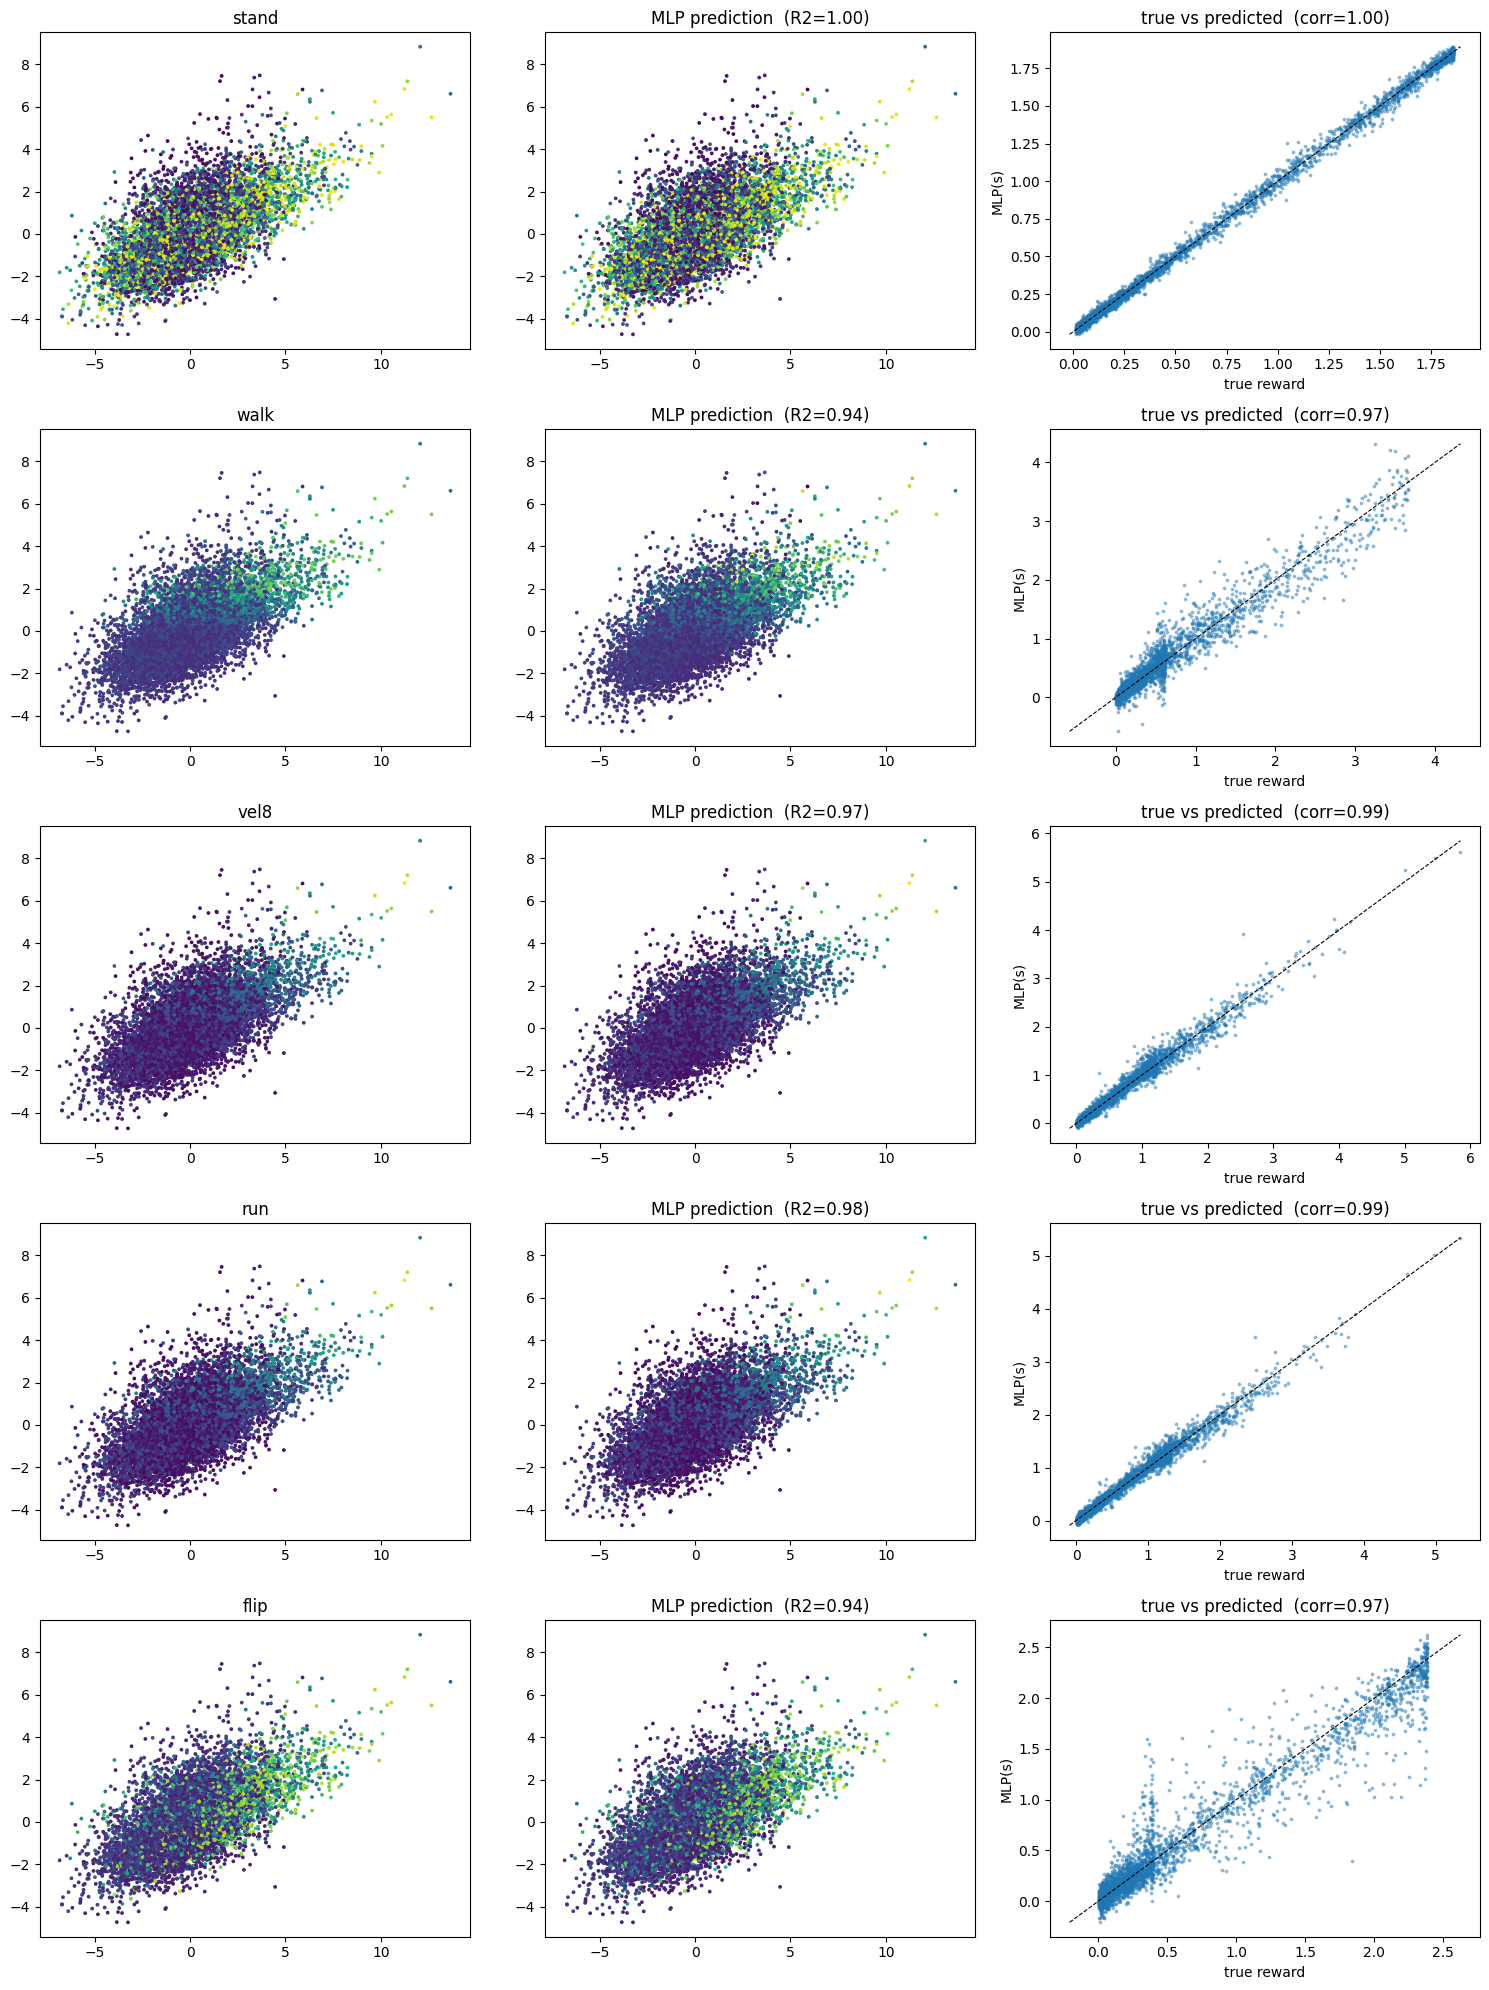

In [63]:
# all tasks (trains one MLP per task)
models = {}
for t in TASKS:
    p, _, _, s = train_reward_net(t, fresh=True)
    models[t] = (p, s)
plot_reconstruction_grid_mlp(models)

## Test 1: finetune B on a single task reward

In [80]:
# ---- L_rec (detached coefficient, as reconstruction_loss in the script; several rewards at once) ----
# def loss_fn(params, lab_obs, lab_r, est_obs):
#     n = lab_obs.shape[0]
#     B_lab = bnet.apply({'params': params}, lab_obs)                      # [n, d]
#     B_est = jax.lax.stop_gradient(bnet.apply({'params': params}, est_obs))
#     Sigma = B_est.T @ B_est / est_obs.shape[0] + RIDGE * jnp.eye(Z_DIM)
#     z_hat = lab_r.T @ B_lab / n                                           # [K, d]  z_hat_k = mean(rbar_k B)
#     W = jax.lax.stop_gradient(jnp.linalg.solve(Sigma, z_hat.T))           # [d, K]  detached coefficients
#     pred = B_lab @ W                                                      # gradients only through B(s_i) of the prediction
#     return ((lab_r - pred) ** 2).mean(0).sum()                            # sum over tasks of per-task (train) eps


ORTHO_COEF = 1
def loss_fn(params, lab_obs, lab_r, est_obs):
    n = lab_obs.shape[0]
    B_lab = bnet.apply({'params': params}, lab_obs)
    B_est_g = bnet.apply({'params': params}, est_obs)                    # with gradient, for the orth term
    B_est = jax.lax.stop_gradient(B_est_g)
    Sigma = B_est.T @ B_est / est_obs.shape[0] + RIDGE * jnp.eye(Z_DIM)
    z_hat = lab_r.T @ B_lab / n
    W = jax.lax.stop_gradient(jnp.linalg.solve(Sigma, z_hat.T))
    rec = ((lab_r - B_lab @ W) ** 2).mean(0).sum()
    Sigma_g = B_est_g.T @ B_est_g / est_obs.shape[0]
    ortho = (Sigma_g ** 2).sum() / Z_DIM - 1.0                           # 0 iff Sigma = I
    return rec + ORTHO_COEF * ortho

opt = optax.adam(LR)

@jax.jit
def train_step(params, opt_state, key, obs_all, lab_obs, lab_r):
    est_obs = obs_all[jax.random.randint(key, (N_EST,), 0, obs_all.shape[0])]
    loss, grads = jax.value_and_grad(loss_fn)(params, lab_obs, lab_r, est_obs)
    updates, opt_state = opt.update(grads, opt_state, params)
    return optax.apply_updates(params, updates), opt_state, loss

@jax.jit
def eval_eps(params, key, obs_all, R_all):
    """Held-out eps for ALL tasks (same as recon_stats): z from fresh fit states, Sigma from fresh states, eval on fresh held-out states."""
    k1, k2, k3 = jax.random.split(key, 3)
    fit, exp, hold = [jax.random.randint(k, (EVAL_N,), 0, obs_all.shape[0]) for k in (k1, k2, k3)]
    B = lambda idx: bnet.apply({'params': params}, obs_all[idx])
    B_fit, B_exp, B_hold = B(fit), B(exp), B(hold)
    m2 = (R_all[fit] ** 2).mean(0)
    z = (R_all[fit] / jnp.sqrt(m2)).T @ B_fit / EVAL_N                    # [K, d]
    cov = B_exp.T @ B_exp / EVAL_N + RIDGE * jnp.eye(Z_DIM)
    rec = B_hold @ jnp.linalg.solve(cov, z.T)                             # [EVAL_N, K]
    r_hold = R_all[hold] / jnp.sqrt(m2)
    return ((r_hold - rec) ** 2).mean(0) / ((r_hold ** 2).mean(0) + 1e-12)

def finetune(train_tasks, steps=STEPS, seed=SEED):
    idx = [TASKS.index(t) for t in train_tasks]
    params, opt_state = init_params, opt.init(init_params)
    key = jax.random.PRNGKey(seed + 1)
    steps_log, eps_log, loss = [], [], float('nan')
    for i in tqdm(range(steps + 1)):
        if i % LOG_EVERY == 0:
            key, k = jax.random.split(key)
            steps_log.append(i)
            eps_log.append(np.asarray(eval_eps(params, k, obs_all, R_all)))
        if i == steps:
            break
        key, k = jax.random.split(key)
        params, opt_state, loss = train_step(params, opt_state, k, obs_all, lab_obs, lab_r[:, idx])
    print(f'  trained on {train_tasks}: final train loss/task = {float(loss) / len(idx):.2e}')
    return params, np.array(steps_log), np.stack(eps_log)                 # eps_log: [T, n_tasks]

In [81]:
def plot_reconstruction_grid(params, tasks=TASKS, n=EVAL_N, n_plot=3000, seed=123, save_path=None):
    """Rows = tasks. Cols = true reward map | reconstructed reward map | true vs reconstructed scatter.
    Reconstruction = B(s)^T Sigma^-1 z, z from fresh fit states, Sigma from fresh states, drawn on fresh held-out states."""
    idx = [TASKS.index(t) for t in tasks]
    k1, k2, k3 = jax.random.split(jax.random.PRNGKey(seed), 3)
    fit, exp, hold = [jax.random.randint(k, (n,), 0, obs_all.shape[0]) for k in (k1, k2, k3)]
    B = lambda i: bnet.apply({'params': params}, obs_all[i])

    r_fit = R_all[fit][:, idx]                                    # [n, K]
    m2 = (r_fit ** 2).mean(0)                                     # scale of rbar_k
    z = (r_fit / jnp.sqrt(m2)).T @ B(fit) / n                     # [K, d]
    B_exp = B(exp)
    cov = B_exp.T @ B_exp / n + RIDGE * jnp.eye(Z_DIM)
    rec = np.asarray(B(hold) @ jnp.linalg.solve(cov, z.T))        # [n, K]
    true = np.asarray(R_all[hold][:, idx] / jnp.sqrt(m2))         # [n, K]

    x = np.asarray(obs_all[hold][:, 16]); y = np.asarray(aux_all[hold][:, 0])   # walker coordinates (as scatter_xy)
    sel = np.random.default_rng(0).choice(n, min(n_plot, n), replace=False)

    K = len(tasks)
    fig, axs = plt.subplots(K, 3, figsize=(15, K * 4))
    axs = axs.reshape(K, 3)
    for k, t in enumerate(tasks):
        r, p = true[:, k], rec[:, k]
        r2 = 1 - ((r - p) ** 2).sum() / ((r - r.mean()) ** 2).sum()
        corr = np.corrcoef(r, p)[0, 1]
        vmin, vmax = min(r.min(), p.min()), max(r.max(), p.max())   # same color scale on both maps
        axs[k, 0].scatter(x, y, c=r, s=3, vmin=vmin, vmax=vmax)
        axs[k, 1].scatter(x, y, c=p, s=3, vmin=vmin, vmax=vmax)
        axs[k, 0].set_title(f'{t}')
        axs[k, 1].set_title(f'Reconstructed Reward Function  (R2={r2:.2f})')
        axs[k, 2].scatter(r[sel], p[sel], s=3, alpha=0.4)
        lo, hi = min(r[sel].min(), p[sel].min()), max(r[sel].max(), p[sel].max())
        axs[k, 2].plot([lo, hi], [lo, hi], 'k--', lw=0.8)
        axs[k, 2].set_title(f'true vs reconstructed  (corr={corr:.2f})')
        axs[k, 2].set_xlabel('true reward'); axs[k, 2].set_ylabel('B(s)^T w')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path)
    plt.show()

100%|█████████▉| 10000/10001 [01:30<00:00, 111.04it/s]


  trained on ['run']: final train loss/task = 1.55e-01


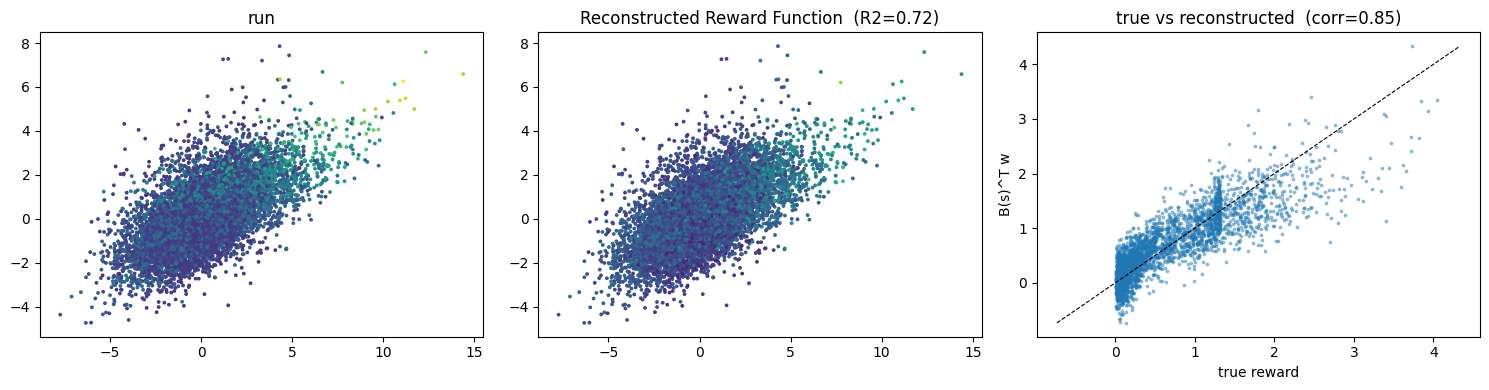

In [82]:
params_t, _, _ = finetune(['run'])
plot_reconstruction_grid(params_t, tasks=['run'])

In [83]:
def diagnose_Lrec(params, t, seed=5):
    j = TASKS.index(t)
    B = lambda i: bnet.apply({'params': params}, obs_all[i])
    scale = jnp.sqrt((R_all[lab_idx, j] ** 2).mean())
    B_lab, r_lab = B(lab_idx), R_all[lab_idx, j] / scale
    Sigma = B_lab.T @ B_lab / N_LABELED + RIDGE * jnp.eye(Z_DIM)      # Sigma on the SAME labeled set
    w = jnp.linalg.solve(Sigma, r_lab @ B_lab / N_LABELED)
    eig = jnp.linalg.eigvalsh(Sigma)
    hold = jax.random.randint(jax.random.PRNGKey(seed), (EVAL_N,), 0, N_DATA)
    r_h = R_all[hold, j] / scale
    train_eps = ((r_lab - B_lab @ w) ** 2).mean() / (r_lab ** 2).mean()
    held_eps = ((r_h - B(hold) @ w) ** 2).mean() / (r_h ** 2).mean()
    print(f'train eps={float(train_eps):.2e}  held-out eps={float(held_eps):.2e}')
    print(f'Sigma eig min={float(eig[0]):.2e} max={float(eig[-1]):.2e}  cond={float(eig[-1] / eig[0]):.1e}  ||w||={float(jnp.linalg.norm(w)):.2f}')

# params_t, _, _ = finetune([t])
diagnose_Lrec(params_t, 'run')

train eps=9.25e-02  held-out eps=1.34e-01
Sigma eig min=1.26e-03 max=1.61e+00  cond=1.3e+03  ||w||=10.89


In [79]:
float(lab_r[:, TASKS.index(t)].mean())

0.7111595273017883

100%|█████████▉| 10000/10001 [01:12<00:00, 138.78it/s]


  trained on ['stand', 'walk', 'vel8', 'run', 'flip']: final train loss/task = 1.40e-01


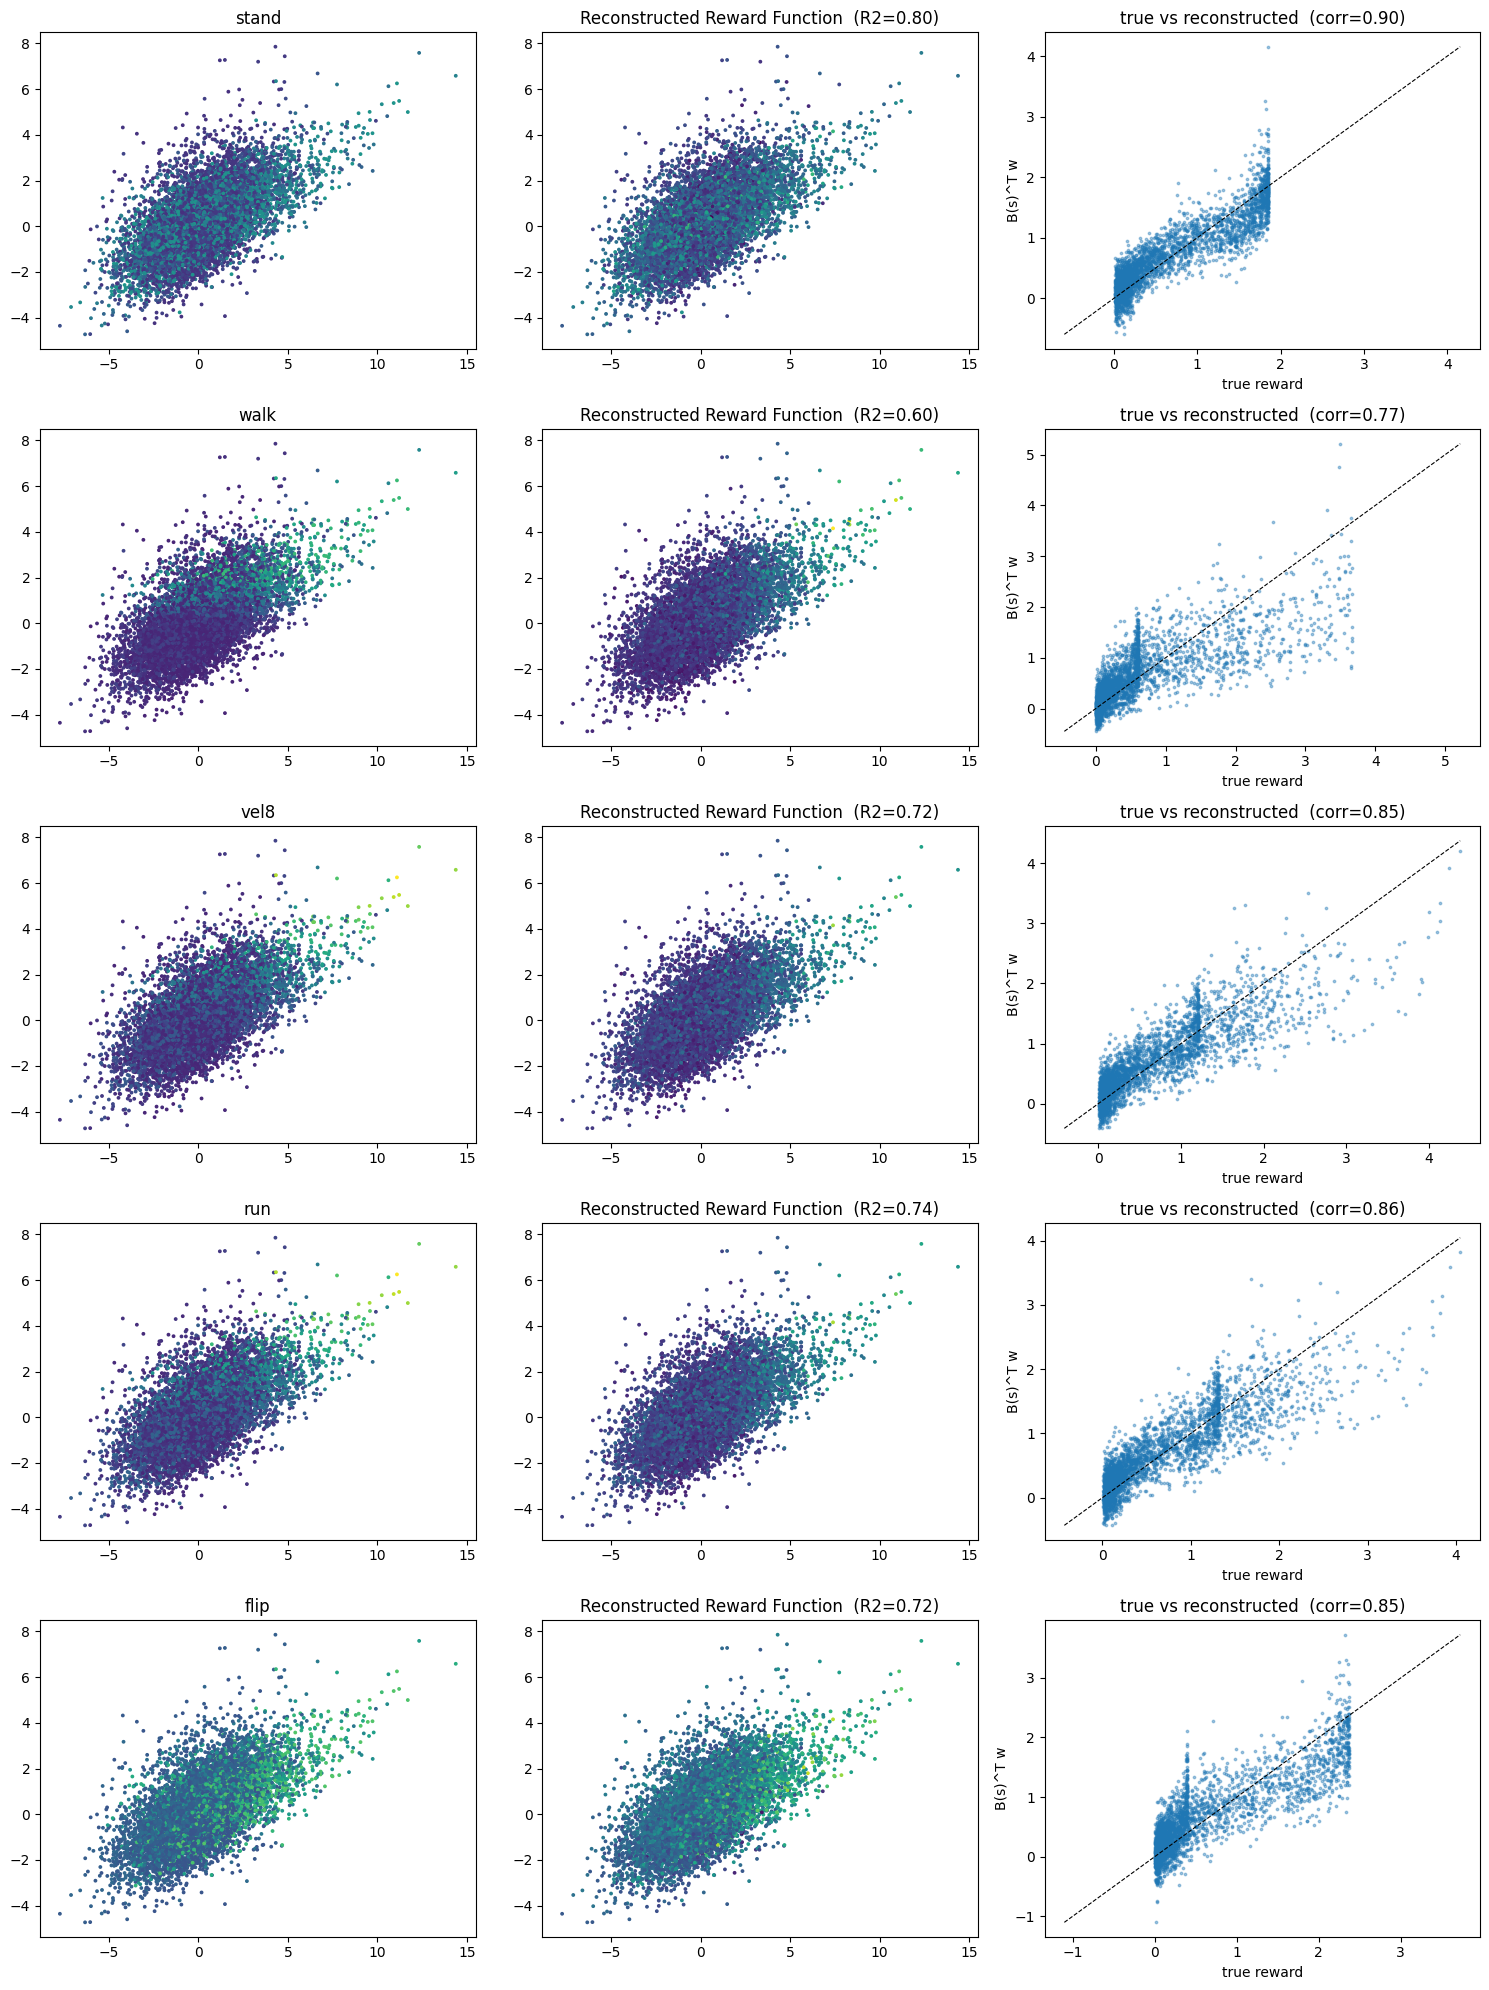

In [66]:
params_all, _, _ = finetune(TASKS)
plot_reconstruction_grid(params_all)

## train_B_fixed_z:

In [72]:
# ---- Cell 1: B(s) with fixed z = ones, trained by direct MSE on r(s) ----
# Z_FIXED = jnp.ones(Z_DIM) / jnp.sqrt(Z_DIM)      # unit norm. For the script's convention use * math.sqrt(Z_DIM)

Z_FIXED = math.sqrt(Z_DIM) * normalize(jax.random.normal(jax.random.PRNGKey(SEED + 123), (Z_DIM,)))
print('||z|| =', float(jnp.linalg.norm(Z_FIXED)))   # = sqrt(d)

def train_B_fixed_z(t, steps=STEPS, fresh=False, lr=3e-4, bs=1024, seed=SEED, pretrained=False):
    """pred(s) = B(s)^T Z_FIXED, trained with MSE against rbar_t.
       fresh=False: minibatches from the 10k labeled set; fresh=True: minibatches from all states.
       pretrained=True: start from init_params (your checkpoint if CHECKPOINT is set) instead of a random init."""
    j = TASKS.index(t)
    scale = jnp.sqrt((R_all[lab_idx, j] ** 2).mean())
    pool = jnp.arange(N_DATA) if fresh else lab_idx
    params = init_params if pretrained else bnet.init(jax.random.PRNGKey(seed), jnp.zeros((1, 24)))['params']
    opt_b = optax.adam(lr)
    opt_state = opt_b.init(params)
    pred_fn = lambda p, o: bnet.apply({'params': p}, o) @ Z_FIXED

    @jax.jit
    def step(params, opt_state, key):
        idx = pool[jax.random.randint(key, (bs,), 0, pool.shape[0])]
        def loss_fn(p):
            return ((pred_fn(p, obs_all[idx]) - R_all[idx, j] / scale) ** 2).mean()
        loss, g = jax.value_and_grad(loss_fn)(params)
        upd, opt_state = opt_b.update(g, opt_state, params)
        return optax.apply_updates(params, upd), opt_state, loss

    @jax.jit
    def eval_eps_b(params, key):
        hold = jax.random.randint(key, (EVAL_N,), 0, N_DATA)
        r = R_all[hold, j] / scale
        return ((pred_fn(params, obs_all[hold]) - r) ** 2).mean() / (r ** 2).mean()

    key = jax.random.PRNGKey(seed + 1)
    steps_log, eps_log = [], []
    for i in tqdm(range(steps + 1)):
        if i % LOG_EVERY == 0:
            key, k = jax.random.split(key)
            steps_log.append(i); eps_log.append(float(eval_eps_b(params, k)))
        if i == steps:
            break
        key, k = jax.random.split(key)
        params, opt_state, loss = step(params, opt_state, k)
    return params, np.array(steps_log), np.array(eps_log), scale

predict_B_fixed_z = lambda p, o: bnet.apply({'params': p}, o) @ Z_FIXED

||z|| = 7.071068286895752


rbar range for run: [0.01, 6.18]   |B^T z| is bounded by sqrt(d) = 7.07 for unit z


  0%|          | 0/10001 [00:00<?, ?it/s]

100%|█████████▉| 10000/10001 [00:08<00:00, 1168.09it/s]


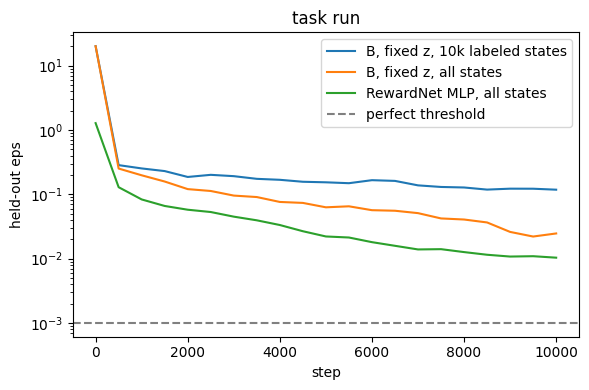

final eps  B fixed z (10k)=1.18e-01  B fixed z (all)=2.46e-02  MLP=1.03e-02


In [75]:
# ---- Cell 2: run it and compare with the direct MLP ----
t = 'run'
r_t = np.asarray(R_all[lab_idx, TASKS.index(t)]); r_t = r_t / np.sqrt((r_t ** 2).mean())
print(f'rbar range for {t}: [{r_t.min():.2f}, {r_t.max():.2f}]   |B^T z| is bounded by sqrt(d) = {math.sqrt(Z_DIM):.2f} for unit z')

pB_lab,   s_log, eps_B_lab,   scaleB = train_B_fixed_z(t, fresh=False)
pB_fresh, _,     eps_B_fresh, _      = train_B_fixed_z(t, fresh=True)
_, _, eps_mlp, _ = train_reward_net(t, fresh=True)          # from the RewardNet experiment

plt.figure(figsize=(6, 4))
plt.semilogy(s_log, eps_B_lab,   label='B, fixed z, 10k labeled states')
plt.semilogy(s_log, eps_B_fresh, label='B, fixed z, all states')
plt.semilogy(s_log, eps_mlp,     label='RewardNet MLP, all states')
plt.axhline(EPS_PERFECT, color='gray', ls='--', label='perfect threshold')
plt.xlabel('step'); plt.ylabel('held-out eps'); plt.title(f'task {t}')
plt.legend(); plt.tight_layout(); plt.show()
print(f'final eps  B fixed z (10k)={eps_B_lab[-1]:.2e}  B fixed z (all)={eps_B_fresh[-1]:.2e}  MLP={eps_mlp[-1]:.2e}')

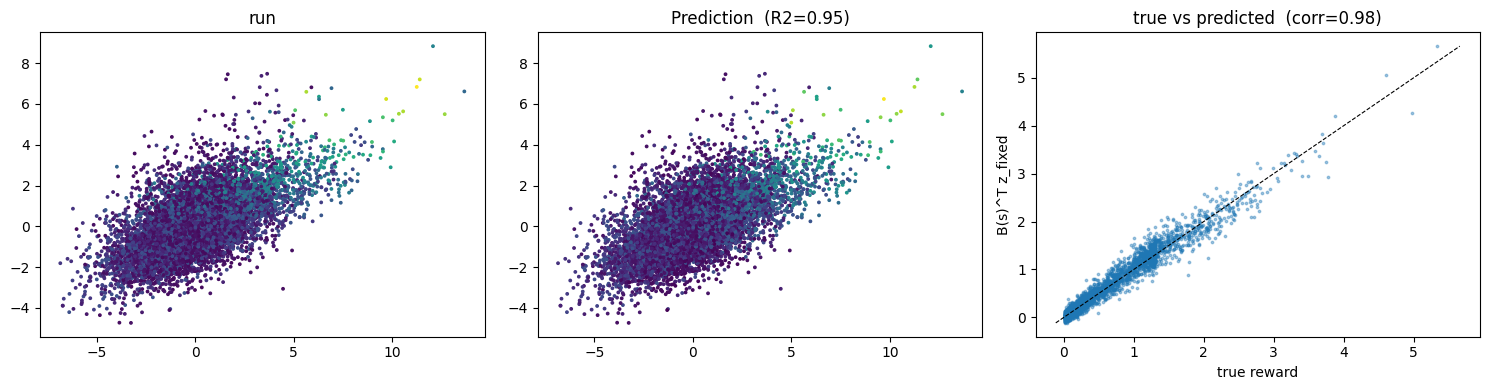

In [76]:
# ---- Cell 3: same 3-column plot, for any predictor ----
def plot_reconstruction_grid_pred(models, predict, n=EVAL_N, n_plot=3000, seed=123, save_path=None):
    """models: {task: (params, scale)}; predict(params, obs) -> predicted rbar. Rows = tasks."""
    hold = jax.random.randint(jax.random.PRNGKey(seed), (n,), 0, obs_all.shape[0])
    x = np.asarray(obs_all[hold][:, 16]); y = np.asarray(aux_all[hold][:, 0])   # walker coordinates
    sel = np.random.default_rng(0).choice(n, min(n_plot, n), replace=False)
    K = len(models)
    fig, axs = plt.subplots(K, 3, figsize=(15, K * 4))
    axs = axs.reshape(K, 3)
    for k, (t, (params, scale)) in enumerate(models.items()):
        r = np.asarray(R_all[hold, TASKS.index(t)] / scale)
        p = np.asarray(predict(params, obs_all[hold]))
        r2 = 1 - ((r - p) ** 2).sum() / ((r - r.mean()) ** 2).sum()
        corr = np.corrcoef(r, p)[0, 1]
        vmin, vmax = min(r.min(), p.min()), max(r.max(), p.max())
        axs[k, 0].scatter(x, y, c=r, s=3, vmin=vmin, vmax=vmax); axs[k, 0].set_title(f'{t}')
        axs[k, 1].scatter(x, y, c=p, s=3, vmin=vmin, vmax=vmax); axs[k, 1].set_title(f'Prediction  (R2={r2:.2f})')
        axs[k, 2].scatter(r[sel], p[sel], s=3, alpha=0.4)
        lo, hi = min(r[sel].min(), p[sel].min()), max(r[sel].max(), p[sel].max())
        axs[k, 2].plot([lo, hi], [lo, hi], 'k--', lw=0.8)
        axs[k, 2].set_title(f'true vs predicted  (corr={corr:.2f})')
        axs[k, 2].set_xlabel('true reward'); axs[k, 2].set_ylabel('B(s)^T z_fixed')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path)
    plt.show()

plot_reconstruction_grid_pred({t: (pB_fresh, scaleB)}, predict_B_fixed_z)
# works for the MLP too: plot_reconstruction_grid_pred({t: (p_fresh, scale)}, lambda p, o: rnet.apply({'params': p}, o))

---

In [100]:
def train_generic(t, mode, steps=STEPS, lr=3e-4, bs=4096, ortho=0.0, init=None,
                  whole_dataset=True, decay=False, seed=SEED):
    """mode: 'fixed_z' | 'lrec_detach' | 'lrec_full'.
       whole_dataset=True : training batches, Sigma estimate and rbar scale use all N_DATA states.
       whole_dataset=False: they use only the 10k labeled states (lab_idx).
       Evaluation is always on fresh held-out states from the whole dataset.
       init: params to start from (None = random init)."""
    j = TASKS.index(t)
    pool = jnp.arange(N_DATA) if whole_dataset else lab_idx
    scale = jnp.sqrt((R_all[pool, j] ** 2).mean())              # rbar scale from the training pool
    params = init if init is not None else bnet.init(jax.random.PRNGKey(seed), jnp.zeros((1, 24)))['params']
    opt_g = optax.adam(optax.cosine_decay_schedule(lr, steps) if decay else lr)
    opt_state = opt_g.init(params)
    B = lambda p, o: bnet.apply({'params': p}, o)

    def loss_fn(p, idx, est_idx):
        B_b, r_b = B(p, obs_all[idx]), R_all[idx, j] / scale
        if mode == 'fixed_z':
            pred, extra = B_b @ Z_FIXED, 0.0
        else:
            B_e = B(p, obs_all[est_idx])
            Sigma = B_e.T @ B_e / est_idx.shape[0] + RIDGE * jnp.eye(Z_DIM)
            w = jnp.linalg.solve(Sigma, r_b @ B_b / bs)
            if mode == 'lrec_detach':
                w = jax.lax.stop_gradient(w)
            pred = B_b @ w
            extra = ortho * ((B_e.T @ B_e / est_idx.shape[0]) ** 2).sum() / Z_DIM if ortho > 0 else 0.0
        return ((r_b - pred) ** 2).mean() + extra

    @jax.jit
    def step(p, s, key):
        k1, k2 = jax.random.split(key)
        idx = pool[jax.random.randint(k1, (bs,), 0, pool.shape[0])]
        est_idx = pool[jax.random.randint(k2, (N_EST,), 0, pool.shape[0])]
        loss, g = jax.value_and_grad(loss_fn)(p, idx, est_idx)
        upd, s = opt_g.update(g, s, p)
        return optax.apply_updates(p, upd), s, loss

    @jax.jit
    def ev(p, key):
        if mode == 'fixed_z':
            hold = jax.random.randint(key, (EVAL_N,), 0, N_DATA)
            r = R_all[hold, j] / scale
            return ((B(p, obs_all[hold]) @ Z_FIXED - r) ** 2).mean() / (r ** 2).mean()
        return eval_eps(p, key, obs_all, R_all)[j]              # lstsq readout, fresh states

    key = jax.random.PRNGKey(seed + 1)
    steps_log, eps_log = [], []
    for i in tqdm(range(steps + 1)):
        if i % LOG_EVERY == 0:
            key, k = jax.random.split(key)
            steps_log.append(i); eps_log.append(float(ev(params, k)))
        if i == steps:
            break
        key, k = jax.random.split(key)
        params, opt_state, _ = step(params, opt_state, k)
    return params, np.array(steps_log), np.array(eps_log)

# t = 'run'
# plt.figure(figsize=(6, 4))
# for mode in ['fixed_z', 'lrec_detach', 'lrec_full']:
#     _, s_log, e = train_generic(t, mode)
#     plt.semilogy(s_log, e, label=mode)
#     print(f'{mode:12s} final eps = {e[-1]:.2e}')
# plt.axhline(EPS_PERFECT, color='gray', ls='--')
# plt.xlabel('step'); plt.ylabel('held-out eps'); plt.title(f'task {t}, same data/lr/batch'); plt.legend(); plt.show()

100%|█████████▉| 10000/10001 [00:23<00:00, 417.10it/s]


fixed-z solution: eps with fixed z = 4.10e-02 | with best lstsq readout = 6.24e-02


100%|█████████▉| 10000/10001 [00:46<00:00, 215.21it/s]


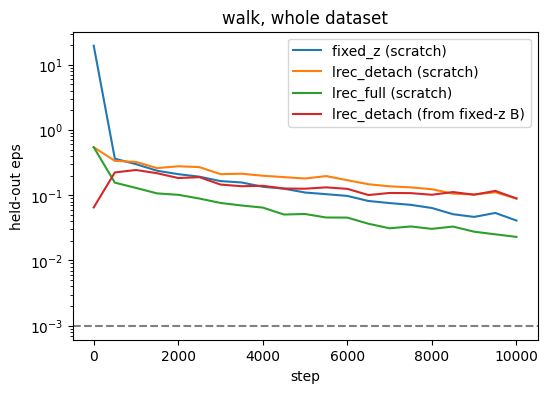

In [86]:
t = 'walk'; j = TASKS.index(t)

# 1) B with fixed z: a B that fits the reward well
p_fz, s_log, e_fz = train_generic(t, 'fixed_z')

# 2) the SAME B read out with the best (lstsq) coefficient = what L_rec measures
e_ls = float(eval_eps(p_fz, jax.random.PRNGKey(0), obs_all, R_all)[j])
print(f'fixed-z solution: eps with fixed z = {e_fz[-1]:.2e} | with best lstsq readout = {e_ls:.2e}')

# 3) L_rec warm-started from that solution vs from scratch
_, _, e_warm = train_generic(t, 'lrec_detach', init=p_fz)
_, _, e_det  = train_generic(t, 'lrec_detach')
_, _, e_full = train_generic(t, 'lrec_full')

plt.figure(figsize=(6, 4))
for name, e in [('fixed_z (scratch)', e_fz), ('lrec_detach (scratch)', e_det),
                ('lrec_full (scratch)', e_full), ('lrec_detach (from fixed-z B)', e_warm)]:
    plt.semilogy(s_log, e, label=name)
plt.axhline(EPS_PERFECT, color='gray', ls='--')
plt.xlabel('step'); plt.ylabel('held-out eps'); plt.title(f'{t}, whole dataset'); plt.legend(); plt.show()

100%|█████████▉| 30000/30001 [01:20<00:00, 373.24it/s]


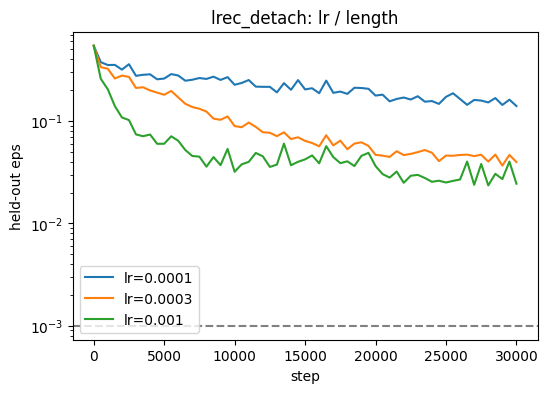

In [87]:
# 4) is it just under-training / learning rate? (L_rec from scratch)
plt.figure(figsize=(6, 4))
for lr in [1e-4, 3e-4, 1e-3]:
    _, s2, e = train_generic(t, 'lrec_detach', lr=lr, steps=30_000)
    plt.semilogy(s2, e, label=f'lr={lr:g}')
plt.axhline(EPS_PERFECT, color='gray', ls='--')
plt.xlabel('step'); plt.ylabel('held-out eps'); plt.title('lrec_detach: lr / length'); plt.legend(); plt.show()

100%|█████████▉| 10000/10001 [00:31<00:00, 314.41it/s]


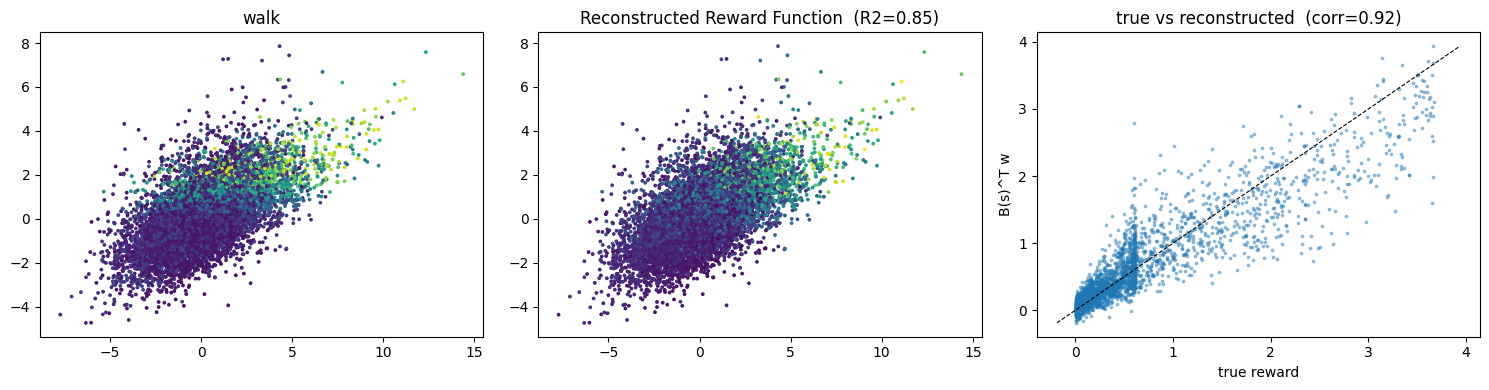

In [94]:
t = 'walk'
p_det, s_log, e_det = train_generic(t, 'lrec_detach', seed=2)
plot_reconstruction_grid(p_det, tasks=[t])

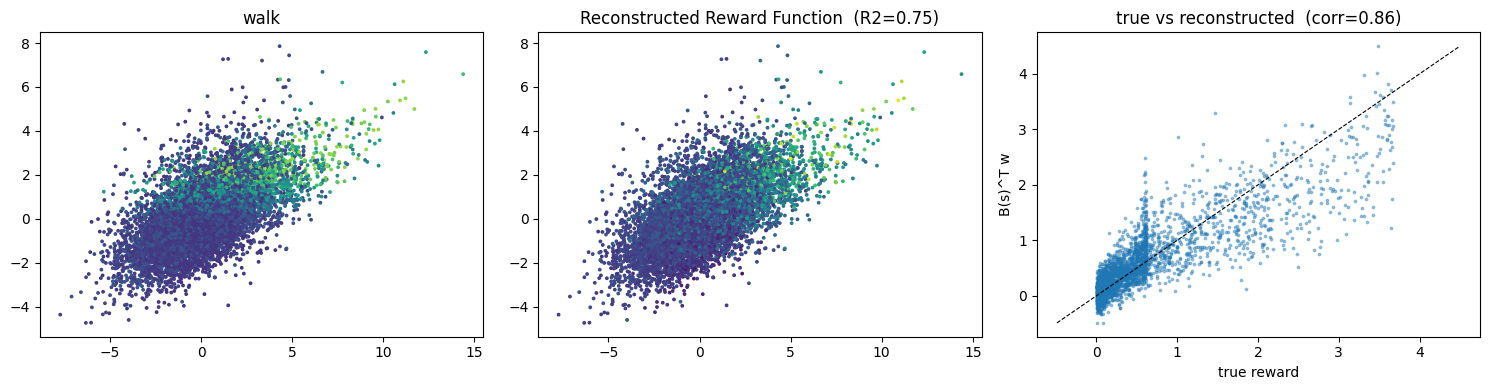

In [97]:
t = 'walk'
p_det, s_log, e_det = train_generic(t, 'lrec_detach', seed=2, whole_dataset=False)
plot_reconstruction_grid(p_det, tasks=[t])

  0%|          | 0/10001 [00:00<?, ?it/s]

100%|█████████▉| 10000/10001 [00:49<00:00, 202.27it/s]


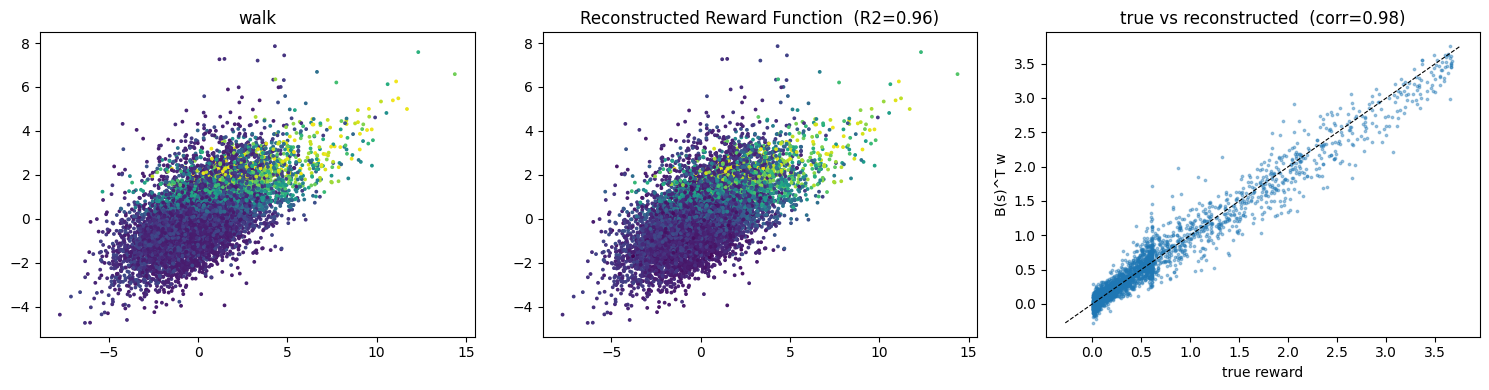

In [95]:
p_full, _, _ = train_generic(t, 'lrec_full', seed=1)
plot_reconstruction_grid(p_full, tasks=[t])

100%|█████████▉| 10000/10001 [00:50<00:00, 197.76it/s]


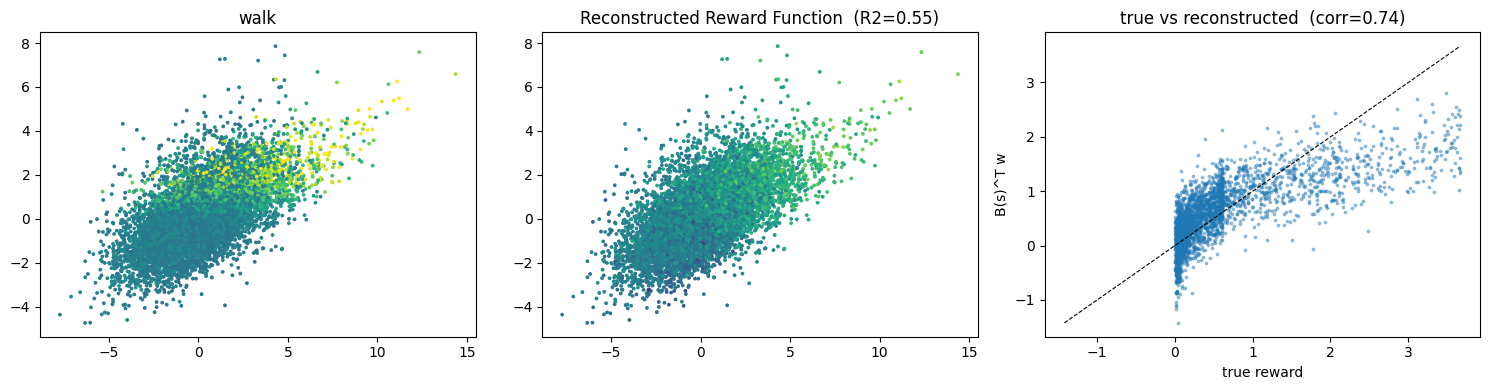

In [ ]:
for size in [1000, 10_000, 100_000, 1_000_000]

lab_idx = jnp.asarray(rng.choice(N_DATA, size=1_000_0, replace=False))
lab_obs = obs_all[lab_idx]
lab_r = R_all[lab_idx] / jnp.sqrt((R_all[lab_idx] ** 2).mean(0))

t = 'walk'
p_full, _, _ = train_generic(t, 'lrec_full', seed=0, whole_dataset=False)
p_det, _, _ = train_generic(t, 'lrec_detach', seed=0, whole_dataset=False)
p_fixed, _, _ = train_generic(t, 'fixed_z', whole_dataset=False)

plot_reconstruction_grid(p_det, tasks=[t])

100%|█████████▉| 10000/10001 [00:25<00:00, 394.15it/s]


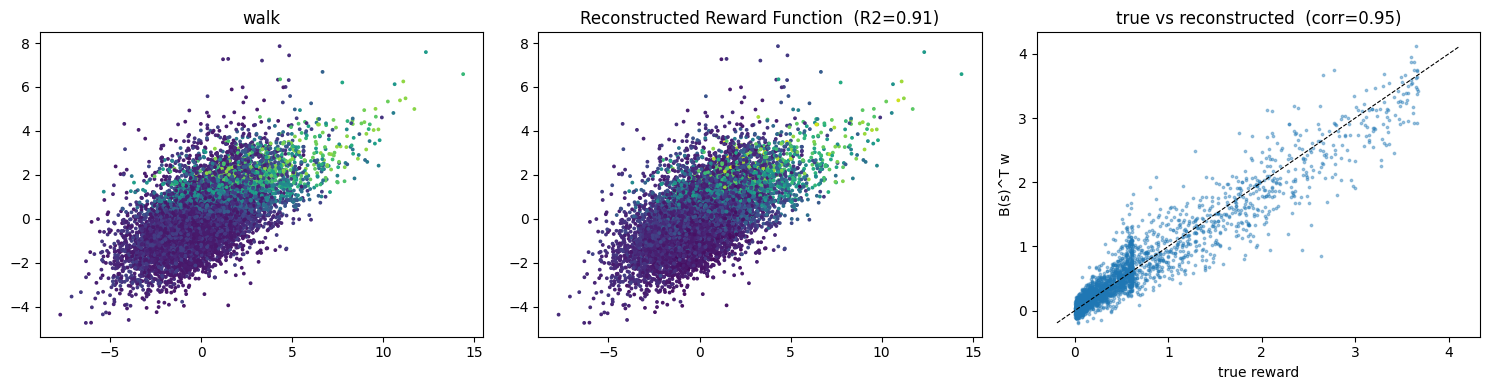

In [91]:
p_full, _, _ = train_generic(t, 'fixed_z')
plot_reconstruction_grid(p_full, tasks=[t])

100%|█████████▉| 10000/10001 [00:49<00:00, 201.29it/s]


size=    1,000  lrec_full    corr=0.5112


100%|█████████▉| 10000/10001 [00:31<00:00, 315.75it/s]


size=    1,000  lrec_detach  corr=0.6680


100%|█████████▉| 10000/10001 [00:23<00:00, 417.97it/s]


...

size=1,000,000  lrec_full    corr=0.9807


100%|█████████▉| 10000/10001 [00:32<00:00, 311.64it/s]


size=1,000,000  lrec_detach  corr=0.9047


100%|█████████▉| 10000/10001 [00:24<00:00, 414.40it/s]


size=1,000,000  fixed_z      corr=0.9700


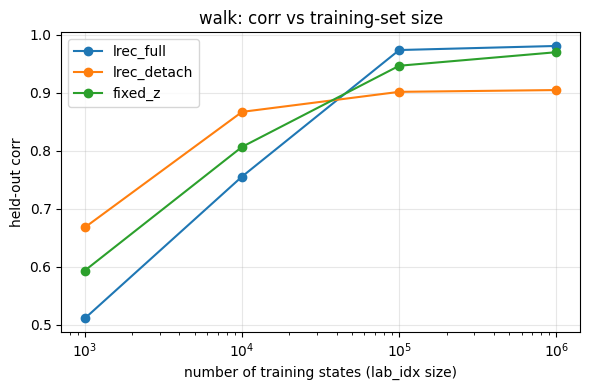

In [130]:
def heldout_corr(params, t, mode, n=EVAL_N, seed=123):
    """Held-out correlation between true reward and reconstruction.
    lrec_*: reconstruction B(s)^T Sigma^-1 z (z from fresh fit states, Sigma from fresh states).
    fixed_z: reconstruction B(s)^T Z_FIXED."""
    j = TASKS.index(t)
    k1, k2, k3 = jax.random.split(jax.random.PRNGKey(seed), 3)
    fit, exp, hold = [jax.random.randint(k, (n,), 0, N_DATA) for k in (k1, k2, k3)]
    B = lambda i: bnet.apply({'params': params}, obs_all[i])
    if mode == 'fixed_z':
        pred = B(hold) @ Z_FIXED
    else:
        r_fit = R_all[fit, j]
        z = (r_fit / jnp.sqrt((r_fit ** 2).mean())) @ B(fit) / n
        B_exp = B(exp)
        cov = B_exp.T @ B_exp / n + RIDGE * jnp.eye(Z_DIM)
        pred = B(hold) @ jnp.linalg.solve(cov, z)
    return float(np.corrcoef(np.asarray(R_all[hold, j]), np.asarray(pred))[0, 1])


t = 'walk'
sizes = [1_000, 10_000, 100_000, 1_000_000]
modes = ['lrec_full', 'lrec_detach', 'fixed_z']
perm = np.random.default_rng(SEED).permutation(N_DATA)          # nested subsets: smaller sets are inside larger ones

corr, params_by = {m: [] for m in modes}, {}
for size in sizes:
    lab_idx = jnp.asarray(perm[:size])                           # train_generic(whole_dataset=False) reads this global
    lab_obs = obs_all[lab_idx]
    lab_r = R_all[lab_idx] / jnp.sqrt((R_all[lab_idx] ** 2).mean(0))
    for m in modes:
        p, _, _ = train_generic(t, m, seed=0, whole_dataset=False)
        params_by[(size, m)] = p
        corr[m].append(heldout_corr(p, t, m))
        print(f'size={size:>9,d}  {m:12s} corr={corr[m][-1]:.4f}')

plt.figure(figsize=(6, 4))
for m in modes:
    plt.plot(sizes, corr[m], 'o-', label=m)
plt.xscale('log'); plt.xlabel('number of training states (lab_idx size)'); plt.ylabel('held-out corr')
plt.title(f'{t}: corr vs training-set size'); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# reconstruction scatter for any run, e.g. L_rec detach trained on 10k states:
# plot_reconstruction_grid(params_by[(10_000, 'lrec_detach')], tasks=[t])